# AeroTrack — Part 9: Tracklet Consolidation and Count Calibration

## Purpose

Part 8 produced 50 provisional global identities from 54 BoT-SORT tracklets. The count is still too fragmented for the scene. Part 9 improves consolidation using the candidate similarities already calculated in Part 7 and the multi-shot findings from Part 6.

**This notebook does not rerun YOLO, BoT-SORT or OSNet.** It reuses:
- The frame-level tracking log.
- The Part 7 candidate similarity table.
- The latest Part 8 identity registry.
- The original source video.

## What this notebook does

1. Rebuild the tracklet-to-identity graph from the existing candidate table.
2. Apply balanced, configurable merge rules.
3. Allow safe chain extension, for example A–B and B–C, only when cluster consistency supports it.
4. Prevent automatic merges of overlapping same-video tracklets.
5. Preserve an editable manual review file.
6. Assess the evidence quality of each tracklet.
7. Detect possible same-frame duplicate boxes for inspection (not automatic merging).
8. Recalculate visible, recently active and cumulative provisional counts.
9. Generate an updated dashboard and annotated video.

## Rules used in this prototype

The default policy uses:
- Direct merge: multi-mean similarity >= 0.83, mutual-best match, and both margins >= 0.015.
- Chain extension: similarity >= 0.84, one candidate ranks first and the other ranks second, and both margins >= 0.015. One side must already belong to a multi-tracklet group.
- Cluster consistency: all same-video cross-pairs in a proposed group must have similarity >= 0.78.
- Same-video temporal overlap blocks automatic merging.
- Cross-video automatic merging is disabled by default because our VisDrone evaluation was within-sequence, not cross-camera.

These are practical prototype settings, not calibrated probabilities. A similarity score is not a probability of identity.

## Important counting distinction

Part 9 reports **provisional identity groups**, not a verified count of real people. Tracklets without usable ReID crops remain separate. Low-quality detections may also be false positives or fragments. The notebook exposes these uncertainties rather than silently deleting them.

## Section 1 — Project paths, input files and matching settings

The paths below follow the AeroTrack structure used in Parts 7 and 8. The notebook prefers the Part 8 registry because it was the registry used to create the counting dashboard. If it is unavailable, it falls back to the Part 7 registry.

Check the printed paths before proceeding.

In [1]:
from pathlib import Path
import time
import math
import json
import hashlib
from itertools import combinations

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display, Video

PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "outputs"

PART7_DIR = OUTPUT_DIR / "part7_global_identity"
PART8_DIR = OUTPUT_DIR / "part8_counting_dashboard"
PART9_DIR = OUTPUT_DIR / "part9_tracklet_consolidation"

PART9_DIR.mkdir(parents=True, exist_ok=True)

TRACK_LOG_PATH = OUTPUT_DIR / "continuity_track_log.csv"
CANDIDATES_PATH = PART7_DIR / "candidate_matches.csv"
PART7_REGISTRY_PATH = PART7_DIR / "global_identity_registry.csv"
PART8_REGISTRY_PATH = PART8_DIR / "global_identity_registry_with_counts.csv"
CROP_MANIFEST_PATH = PART7_DIR / "crop_manifest.csv"

# Use the latest Part 8 registry when available.
REGISTRY_PATH = (
    PART8_REGISTRY_PATH
    if PART8_REGISTRY_PATH.exists()
    else PART7_REGISTRY_PATH
)

VIDEO_SOURCES = [
    {
        "video_id": "session_01",
        "video_path": DATA_DIR / "drone_video.mov",
        "track_log_path": TRACK_LOG_PATH,
        "segment_start_seconds": None
    }
]

# Balanced prototype matching policy.
DIRECT_MATCH_THRESHOLD = 0.83
DIRECT_MIN_MARGIN = 0.015

CHAIN_EXTENSION_THRESHOLD = 0.84
CHAIN_EXTENSION_MIN_MARGIN = 0.015
CHAIN_EXTENSION_MAX_RANK = 2

# Every same-video pair inside a merged cluster must meet this floor.
CLUSTER_MIN_PAIR_SIMILARITY = 0.78

# Candidates are exported for review from this similarity level upward.
REVIEW_THRESHOLD = 0.75

# Cross-video matching has not been validated with known repeated people.
ALLOW_CROSS_VIDEO_AUTO_MERGES = False

# Visibility counting.
VISIBILITY_GRACE_SECONDS = 1.0

# Output controls.
CREATE_ANNOTATED_VIDEO = True
CREATE_CANDIDATE_CONTACT_SHEET = True
ANNOTATED_VIDEO_FPS = None  # None preserves source FPS.

print("Project:", PROJECT_DIR)
print("Tracking log:", TRACK_LOG_PATH, TRACK_LOG_PATH.exists())
print("Candidate table:", CANDIDATES_PATH, CANDIDATES_PATH.exists())
print("Registry selected:", REGISTRY_PATH, REGISTRY_PATH.exists())
print("Source video:", VIDEO_SOURCES[0]["video_path"])
print("Output folder:", PART9_DIR)

Project: c:\Users\anyan\source\repos\AeroTrack
Tracking log: c:\Users\anyan\source\repos\AeroTrack\outputs\continuity_track_log.csv True
Candidate table: c:\Users\anyan\source\repos\AeroTrack\outputs\part7_global_identity\candidate_matches.csv True
Registry selected: c:\Users\anyan\source\repos\AeroTrack\outputs\part8_counting_dashboard\global_identity_registry_with_counts.csv True
Source video: c:\Users\anyan\source\repos\AeroTrack\data\drone_video.mov
Output folder: c:\Users\anyan\source\repos\AeroTrack\outputs\part9_tracklet_consolidation


## Section 2 — Load the tracking log, candidate table and latest registry

The Part 7 candidate table contains precomputed multi-mean and multi-max similarity scores. We use those scores directly; no embedding model is loaded in Part 9.

The candidate table's old `global_id_a`, `global_id_b` and `cluster_decision` fields are not trusted for the new run. Part 9 rebuilds the grouping from the pair scores and the new merge policy.

In [2]:
for required_path in [TRACK_LOG_PATH, CANDIDATES_PATH, REGISTRY_PATH]:
    if not required_path.exists():
        raise FileNotFoundError(
            f"Required Part 9 input not found: {required_path}"
        )

track_log = pd.read_csv(TRACK_LOG_PATH)
candidate_df = pd.read_csv(CANDIDATES_PATH)
registry = pd.read_csv(REGISTRY_PATH)

required_log_columns = {
    "frame", "track_id", "confidence", "x1", "y1", "x2", "y2"
}
required_candidate_columns = {
    "tracklet_a", "tracklet_b", "multi_mean_similarity",
    "multi_max_similarity", "rank_for_a", "rank_for_b",
    "margin_for_a", "margin_for_b", "mutual_best"
}
required_registry_columns = {
    "global_id", "tracklet_key", "video_id", "track_id"
}

missing_log = required_log_columns - set(track_log.columns)
missing_candidate = required_candidate_columns - set(candidate_df.columns)
missing_registry = required_registry_columns - set(registry.columns)

if missing_log:
    raise ValueError(f"Tracking log missing columns: {missing_log}")
if missing_candidate:
    raise ValueError(f"Candidate table missing columns: {missing_candidate}")
if missing_registry:
    raise ValueError(f"Registry missing columns: {missing_registry}")

print("Tracking observations:", len(track_log))
print("Candidate pairs:", len(candidate_df))
print("Registry rows:", len(registry))
print("Registry global IDs:", registry["global_id"].nunique())
print("Registry source:", REGISTRY_PATH)

Tracking observations: 7179
Candidate pairs: 366
Registry rows: 54
Registry global IDs: 50
Registry source: c:\Users\anyan\source\repos\AeroTrack\outputs\part8_counting_dashboard\global_identity_registry_with_counts.csv


## Section 3 — Attach video IDs and inspect source video metadata

The Experiment 008 tracking log may not contain a `video_id` column because it was produced before the multi-video workflow. In that case the configured source list supplies the ID.

Each video must have a unique ID. Tracker ID 14 in `session_01` is a different local tracklet from tracker ID 14 in `session_02`.

In [3]:
if not VIDEO_SOURCES:
    raise ValueError("Configure at least one video in VIDEO_SOURCES.")

video_ids = [str(item["video_id"]) for item in VIDEO_SOURCES]
if len(video_ids) != len(set(video_ids)):
    raise ValueError("video_id values in VIDEO_SOURCES must be unique.")

source_by_id = {
    str(item["video_id"]): item
    for item in VIDEO_SOURCES
}

if "video_id" not in track_log.columns:
    if len(VIDEO_SOURCES) != 1:
        raise ValueError(
            "Tracking log has no video_id column. For multiple videos, "
            "generate a log with video_id for each row."
        )
    track_log["video_id"] = video_ids[0]

track_log["video_id"] = track_log["video_id"].astype(str)
track_log["frame"] = pd.to_numeric(track_log["frame"], errors="coerce")
track_log["track_id"] = pd.to_numeric(track_log["track_id"], errors="coerce")

track_log = track_log.dropna(
    subset=["frame", "track_id", "confidence", "x1", "y1", "x2", "y2"]
).copy()

track_log["frame"] = track_log["frame"].astype(int)
track_log["track_id"] = track_log["track_id"].astype(int)

video_metadata = {}

for source in VIDEO_SOURCES:
    video_id = str(source["video_id"])
    video_path = Path(source["video_path"])

    if not video_path.exists():
        raise FileNotFoundError(f"{video_id}: source video not found: {video_path}")

    cap = cv2.VideoCapture(str(video_path))
    if not cap.isOpened():
        raise RuntimeError(f"{video_id}: could not open source video.")

    fps = cap.get(cv2.CAP_PROP_FPS)
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    cap.release()

    if fps <= 0:
        raise ValueError(f"{video_id}: invalid FPS.")

    video_log = track_log[track_log["video_id"] == video_id]

    if video_log.empty:
        raise ValueError(f"{video_id}: no tracking rows found in the log.")

    configured_start = source.get("segment_start_seconds")

    if configured_start is not None:
        segment_start = float(configured_start)
    elif "time_seconds" in video_log.columns:
        valid = pd.to_numeric(
            video_log["time_seconds"], errors="coerce"
        ).dropna()

        if valid.empty:
            segment_start = 0.0
        else:
            valid_rows = video_log.loc[valid.index]
            offsets = (
                pd.to_numeric(valid_rows["time_seconds"], errors="coerce")
                - valid_rows["frame"] / fps
            )
            segment_start = float(offsets.median())
            deviation = float((offsets - segment_start).abs().max())

            if deviation > 0.10:
                raise ValueError(
                    f"{video_id}: inconsistent frame/time mapping "
                    f"({deviation:.3f}s). Set segment_start_seconds explicitly."
                )
    else:
        segment_start = 0.0

    fallback_time = segment_start + video_log["frame"] / fps

    if "time_seconds" not in video_log.columns:
        track_log.loc[video_log.index, "time_seconds"] = fallback_time
    else:
        times = pd.to_numeric(
            video_log["time_seconds"], errors="coerce"
        ).fillna(fallback_time)
        track_log.loc[video_log.index, "time_seconds"] = times

    video_metadata[video_id] = {
        "video_path": video_path,
        "fps": float(fps),
        "width": width,
        "height": height,
        "frame_count": frame_count,
        "segment_start_seconds": segment_start
    }

    print(
        f"{video_id}: {width}x{height}, {fps:.2f} FPS, "
        f"{frame_count} source frames, segment start {segment_start:.2f}s"
    )

# Rebuild unique local tracklet keys.
track_log["tracklet_key"] = (
    track_log["video_id"] + "::track_" + track_log["track_id"].astype(str)
)

print("Local tracklets in tracking log:", track_log["tracklet_key"].nunique())

session_01: 3840x2160, 29.97 FPS, 2272 source frames, segment start 5.00s
Local tracklets in tracking log: 54


## Section 4 — Build tracklet quality and time-interval metadata

This section does not remove any tracklets. It classifies the available evidence so the final report can distinguish:
- Tracklets with usable OSNet crops.
- Short tracklets with too few observations.
- Tracklets that existed but did not produce usable ReID crops.

A tracklet with insufficient ReID evidence still remains in the provisional count as a separate identity group.

In [4]:
# Bring crop count and prior registry status into tracklet quality diagnostics.
registry["tracklet_key"] = registry["tracklet_key"].astype(str)
registry["video_id"] = registry["video_id"].astype(str)
registry["track_id"] = pd.to_numeric(
    registry["track_id"], errors="coerce"
).astype(int)

if "crop_count" not in registry.columns:
    registry["crop_count"] = 0

registry["crop_count"] = pd.to_numeric(
    registry["crop_count"], errors="coerce"
).fillna(0).astype(int)

crop_count_map = dict(
    zip(registry["tracklet_key"], registry["crop_count"])
)

prior_gid_map = dict(
    zip(
        registry["tracklet_key"],
        registry["global_id"].astype(str)
    )
)

track_quality_rows = []

for tracklet_key, group in track_log.groupby("tracklet_key"):
    video_id = str(group["video_id"].iloc[0])
    fps = video_metadata[video_id]["fps"]

    first_frame = int(group["frame"].min())
    last_frame = int(group["frame"].max())
    observations = int(len(group))
    duration_seconds = max(0.0, (last_frame - first_frame) / fps)

    widths = (group["x2"] - group["x1"]).clip(lower=0)
    heights = (group["y2"] - group["y1"]).clip(lower=0)
    areas = widths * heights

    crop_count = int(crop_count_map.get(tracklet_key, 0))

    if crop_count > 0:
        evidence_status = "reid_eligible"
    elif observations < 5:
        evidence_status = "short_tracklet"
    else:
        evidence_status = "no_usable_reid_crops"

    track_quality_rows.append({
        "tracklet_key": tracklet_key,
        "video_id": video_id,
        "track_id": int(group["track_id"].iloc[0]),
        "first_frame": first_frame,
        "last_frame": last_frame,
        "first_seen_seconds": float(group["time_seconds"].min()),
        "last_seen_seconds": float(group["time_seconds"].max()),
        "duration_seconds": duration_seconds,
        "observations": observations,
        "mean_confidence": float(group["confidence"].mean()),
        "median_confidence": float(group["confidence"].median()),
        "median_box_width": float(widths.median()),
        "median_box_height": float(heights.median()),
        "median_box_area": float(areas.median()),
        "crop_count": crop_count,
        "prior_global_id": prior_gid_map.get(tracklet_key, ""),
        "evidence_status": evidence_status
    })

track_quality = pd.DataFrame(track_quality_rows)

# Use the actual log as the source of truth for all observed tracklets.
log_keys = set(track_quality["tracklet_key"])
registry_keys = set(registry["tracklet_key"])

missing_registry_keys = sorted(log_keys - registry_keys)
registry_only_keys = sorted(registry_keys - log_keys)

print("Tracklets in log:", len(log_keys))
print("Tracklets missing from registry:", len(missing_registry_keys))
print("Registry-only tracklets:", len(registry_only_keys))

if missing_registry_keys:
    print("Missing registry examples:", missing_registry_keys[:10])

display(
    track_quality["evidence_status"]
    .value_counts()
    .rename_axis("evidence_status")
    .reset_index(name="tracklets")
)

display(
    track_quality.sort_values(
        ["observations", "median_confidence"],
        ascending=[True, True]
    ).head(20)
)

Tracklets in log: 54
Tracklets missing from registry: 0
Registry-only tracklets: 0


,evidence_status,tracklets
0,reid_eligible,35
1,short_tracklet,17
2,no_usable_reid_crops,2


,tracklet_key,video_id,track_id,first_frame,last_frame,first_seen_seconds,last_seen_seconds,duration_seconds,observations,mean_confidence,median_confidence,median_box_width,median_box_height,median_box_area,crop_count,prior_global_id,evidence_status
22,session_01::track_190,session_01,190,621,621,25.72,25.72,0.000000,1,0.361499,0.361499,17.675049,45.994637,812.957447,0,G0036,short_tracklet
32,session_01::track_241,session_01,241,818,818,32.29,32.29,0.000000,1,0.369898,0.369898,43.601562,75.753388,3302.966071,0,G0045,short_tracklet
41,session_01::track_32,session_01,32,57,57,6.90,6.90,0.000000,1,0.369907,0.369907,51.683594,68.730408,3552.234471,0,G0011,short_tracklet
8,session_01::track_148,session_01,148,320,320,15.68,15.68,0.000000,1,0.375071,0.375071,24.709656,48.717041,1203.781313,0,G0025,short_tracklet
51,session_01::track_85,session_01,85,153,153,10.11,10.11,0.000000,1,0.516872,0.516872,19.169434,43.535645,834.553647,0,G0017,short_tracklet
20,session_01::track_189,session_01,189,619,619,25.65,25.65,0.000000,1,0.519459,0.519459,14.447754,26.319916,380.263666,0,G0035,short_tracklet
9,session_01::track_150,session_01,150,328,328,15.94,15.94,0.000000,1,0.544666,0.544666,9.330566,20.677551,192.933265,0,G0026,short_tracklet
2,session_01::track_106,session_01,106,188,188,11.27,11.27,0.000000,1,0.644340,0.644340,122.776367,117.031982,14368.761647,0,G0020,short_tracklet
1,session_01::track_103,session_01,103,185,187,11.17,11.24,0.066733,2,0.359634,0.359634,26.853271,13.848618,372.435173,0,G0019,short_tracklet
38,session_01::track_270,session_01,270,883,884,34.46,34.50,0.033367,2,0.500046,0.500046,281.272461,505.292866,142138.067480,0,G0050,short_tracklet


## Section 5 — Validate and prepare candidate similarity pairs

We use the multi-mean similarity as the primary score and multi-max as supporting information.

The candidate table is checked against the tracklets in the current tracking log. Old Global IDs stored in the candidate CSV are ignored because Part 9 rebuilds identity groups from scratch.

In [5]:
candidate_df["tracklet_a"] = candidate_df["tracklet_a"].astype(str)
candidate_df["tracklet_b"] = candidate_df["tracklet_b"].astype(str)

numeric_candidate_columns = [
    "multi_mean_similarity",
    "multi_max_similarity",
    "rank_for_a",
    "rank_for_b",
    "margin_for_a",
    "margin_for_b"
]

for column in numeric_candidate_columns:
    candidate_df[column] = pd.to_numeric(
        candidate_df[column], errors="coerce"
    )

candidate_df["mutual_best"] = (
    candidate_df["mutual_best"]
    .astype(str)
    .str.strip()
    .str.lower()
    .isin(["true", "1", "yes"])
)

if "video_a" not in candidate_df.columns:
    candidate_df["video_a"] = candidate_df["tracklet_a"].str.split("::").str[0]

if "video_b" not in candidate_df.columns:
    candidate_df["video_b"] = candidate_df["tracklet_b"].str.split("::").str[0]

candidate_df["video_a"] = candidate_df["video_a"].astype(str)
candidate_df["video_b"] = candidate_df["video_b"].astype(str)
candidate_df["same_video"] = (
    candidate_df["video_a"] == candidate_df["video_b"]
)

# Keep only pairs whose endpoints exist in the current tracking log.
candidate_df["endpoints_in_log"] = (
    candidate_df["tracklet_a"].isin(log_keys) &
    candidate_df["tracklet_b"].isin(log_keys)
)

candidate_df = candidate_df[
    candidate_df["endpoints_in_log"]
].copy()

# Pair lookup used for the complete-link cluster consistency check.
mean_similarity_lookup = {}

for _, row in candidate_df.iterrows():
    pair_key = frozenset([row["tracklet_a"], row["tracklet_b"]])
    mean_similarity_lookup[pair_key] = float(
        row["multi_mean_similarity"]
    )

print("Usable candidate pairs:", len(candidate_df))
print(
    "Candidate pairs at/above review threshold:",
    int((candidate_df["multi_mean_similarity"] >= REVIEW_THRESHOLD).sum())
)

display(
    candidate_df.sort_values(
        "multi_mean_similarity",
        ascending=False
    ).head(20)[
        [
            "tracklet_a", "tracklet_b",
            "multi_mean_similarity", "multi_max_similarity",
            "rank_for_a", "rank_for_b",
            "margin_for_a", "margin_for_b", "mutual_best"
        ]
    ]
)

Usable candidate pairs: 366
Candidate pairs at/above review threshold: 25


,tracklet_a,tracklet_b,multi_mean_similarity,multi_max_similarity,rank_for_a,rank_for_b,margin_for_a,margin_for_b,mutual_best
0,session_01::track_14,session_01::track_68,0.939585,0.875895,1,1,0.133308,0.137072,True
1,session_01::track_234,session_01::track_250,0.916946,0.906195,1,1,0.063461,0.029202,True
2,session_01::track_134,session_01::track_169,0.909670,0.879644,1,1,0.108802,0.016796,True
3,session_01::track_169,session_01::track_267,0.892875,0.841541,2,1,0.016796,0.092007,False
4,session_01::track_170,session_01::track_6,0.888373,0.842266,1,1,0.381024,0.342978,True
5,session_01::track_250,session_01::track_5,0.887744,0.830695,2,1,0.029202,0.003958,False
6,session_01::track_171,session_01::track_5,0.883786,0.884341,1,2,0.121608,0.003958,False
7,session_01::track_108,session_01::track_160,0.869218,0.783973,1,1,0.074194,0.015275,True
8,session_01::track_160,session_01::track_265,0.853942,0.863023,2,1,0.015275,0.058919,False
9,session_01::track_234,session_01::track_5,0.853485,0.836525,2,3,0.063461,0.003958,False


## Section 6 — Create or reload the editable manual merge file

This file includes candidate pairs with multi-mean similarity >= the review threshold. It is not necessary to manually inspect every pair.

You can optionally set:
- `manual_decision = same`
- `manual_decision = different`
- `manual_decision = uncertain`

The notebook preserves decisions from a previous run. Manual `same` decisions can override an appearance threshold, but the system still blocks impossible same-video temporal overlaps. Manual `different` decisions prevent those two tracklets from being placed in the same identity cluster, including through a chain.

In [6]:
MANUAL_DECISIONS_PATH = PART9_DIR / "manual_merge_decisions.csv"

review_template = candidate_df[
    candidate_df["multi_mean_similarity"] >= REVIEW_THRESHOLD
].copy()

review_template["suggested_action"] = np.where(
    (review_template["multi_mean_similarity"] >= DIRECT_MATCH_THRESHOLD) &
    review_template["mutual_best"] &
    (review_template["margin_for_a"] >= DIRECT_MIN_MARGIN) &
    (review_template["margin_for_b"] >= DIRECT_MIN_MARGIN),
    "strong_mutual_candidate",
    np.where(
        (review_template["multi_mean_similarity"] >= CHAIN_EXTENSION_THRESHOLD) &
        (review_template["rank_for_a"].isin([1, 2])) &
        (review_template["rank_for_b"].isin([1, 2])),
        "possible_chain_candidate",
        "inspect_if_useful"
    )
)

review_template["manual_decision"] = ""
review_template["review_notes"] = ""

if MANUAL_DECISIONS_PATH.exists():
    previous_decisions = pd.read_csv(MANUAL_DECISIONS_PATH)

    if {
        "tracklet_a", "tracklet_b", "manual_decision"
    }.issubset(previous_decisions.columns):
        previous_decisions["pair_key"] = previous_decisions.apply(
            lambda row: tuple(sorted([
                str(row["tracklet_a"]),
                str(row["tracklet_b"])
            ])),
            axis=1
        )

        review_template["pair_key"] = review_template.apply(
            lambda row: tuple(sorted([
                str(row["tracklet_a"]),
                str(row["tracklet_b"])
            ])),
            axis=1
        )

        decision_map = dict(zip(
            previous_decisions["pair_key"],
            previous_decisions["manual_decision"].fillna("").astype(str)
        ))

        notes_map = (
            dict(zip(
                previous_decisions["pair_key"],
                previous_decisions["review_notes"].fillna("").astype(str)
            ))
            if "review_notes" in previous_decisions.columns
            else {}
        )

        review_template["manual_decision"] = (
            review_template["pair_key"].map(decision_map).fillna("")
        )
        review_template["review_notes"] = (
            review_template["pair_key"].map(notes_map).fillna("")
        )

        review_template = review_template.drop(columns=["pair_key"])

review_columns = [
    "tracklet_a", "tracklet_b",
    "multi_mean_similarity", "multi_max_similarity",
    "rank_for_a", "rank_for_b",
    "margin_for_a", "margin_for_b",
    "mutual_best", "same_video",
    "suggested_action", "manual_decision", "review_notes"
]

review_template[review_columns].sort_values(
    "multi_mean_similarity",
    ascending=False
).to_csv(MANUAL_DECISIONS_PATH, index=False)

print("Manual decision file:", MANUAL_DECISIONS_PATH)
print("Candidate rows in review file:", len(review_template))
print("Existing manual decisions preserved:", int(
    review_template["manual_decision"].astype(str).str.strip().ne("").sum()
))

display(
    review_template[review_columns]
    .sort_values("multi_mean_similarity", ascending=False)
    .head(25)
)

Manual decision file: c:\Users\anyan\source\repos\AeroTrack\outputs\part9_tracklet_consolidation\manual_merge_decisions.csv
Candidate rows in review file: 25
Existing manual decisions preserved: 0


C:\Users\anyan\AppData\Local\Temp\ipykernel_9156\3383960374.py:49: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  previous_decisions["manual_decision"].fillna("").astype(str)
C:\Users\anyan\AppData\Local\Temp\ipykernel_9156\3383960374.py:55: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  previous_decisions["review_notes"].fillna("").astype(str)


,tracklet_a,tracklet_b,multi_mean_similarity,multi_max_similarity,rank_for_a,rank_for_b,margin_for_a,margin_for_b,mutual_best,same_video,suggested_action,manual_decision,review_notes
0,session_01::track_14,session_01::track_68,0.939585,0.875895,1,1,0.133308,0.137072,True,True,strong_mutual_candidate,,
1,session_01::track_234,session_01::track_250,0.916946,0.906195,1,1,0.063461,0.029202,True,True,strong_mutual_candidate,,
2,session_01::track_134,session_01::track_169,0.909670,0.879644,1,1,0.108802,0.016796,True,True,strong_mutual_candidate,,
3,session_01::track_169,session_01::track_267,0.892875,0.841541,2,1,0.016796,0.092007,False,True,possible_chain_candidate,,
4,session_01::track_170,session_01::track_6,0.888373,0.842266,1,1,0.381024,0.342978,True,True,strong_mutual_candidate,,
5,session_01::track_250,session_01::track_5,0.887744,0.830695,2,1,0.029202,0.003958,False,True,possible_chain_candidate,,
6,session_01::track_171,session_01::track_5,0.883786,0.884341,1,2,0.121608,0.003958,False,True,possible_chain_candidate,,
7,session_01::track_108,session_01::track_160,0.869218,0.783973,1,1,0.074194,0.015275,True,True,strong_mutual_candidate,,
8,session_01::track_160,session_01::track_265,0.853942,0.863023,2,1,0.015275,0.058919,False,True,possible_chain_candidate,,
9,session_01::track_234,session_01::track_5,0.853485,0.836525,2,3,0.063461,0.003958,False,True,inspect_if_useful,,


## Section 7 — Build the candidate graph and merge safely

The graph has one node per local tracklet and candidate matches as edges.

### Pass 1: direct mutual-best links

Automatically propose a link when:
- Same video (unless cross-video auto merging is explicitly enabled).
- Multi-mean >= `DIRECT_MATCH_THRESHOLD`.
- Mutual-best is true.
- Both margins >= `DIRECT_MIN_MARGIN`.

### Pass 2: chain extension

A candidate can extend an existing multi-tracklet group when:
- Multi-mean >= `CHAIN_EXTENSION_THRESHOLD`.
- One endpoint ranks the other first and the other ranks it second.
- Both margins meet the chain-extension margin.
- At least one endpoint already belongs to a multi-tracklet group.

### Cluster safeguards

Before any automatic merge:
- No same-video member intervals may overlap.
- Every same-video cross-pair between the two proposed clusters must have a candidate similarity >= `CLUSTER_MIN_PAIR_SIMILARITY`.
- No manually labelled `different` pair may be brought into the same cluster.

This is stricter than basic single-link clustering and helps prevent a chain of weak matches from merging unrelated people.

In [7]:
all_tracklet_keys = sorted(log_keys)

parent = {key: key for key in all_tracklet_keys}
cluster_members = {key: {key} for key in all_tracklet_keys}

track_meta = (
    track_quality.set_index("tracklet_key")
    .to_dict("index")
)

def find_root(key):
    while parent[key] != key:
        parent[key] = parent[parent[key]]
        key = parent[key]
    return key

def clusters_overlap(members_a, members_b):
    # A person cannot be represented by two independent tracklets that
    # overlap in time in the same video under automatic matching.
    for key_a in members_a:
        meta_a = track_meta[key_a]

        for key_b in members_b:
            meta_b = track_meta[key_b]

            if meta_a["video_id"] != meta_b["video_id"]:
                continue

            overlaps = not (
                meta_a["last_frame"] < meta_b["first_frame"] or
                meta_b["last_frame"] < meta_a["first_frame"]
            )

            if overlaps:
                return True, (key_a, key_b)

    return False, None

# Build hard-negative pairs from the manual review file.
manual_different_pairs = set()
manual_same_pairs = set()

for _, row in review_template.iterrows():
    decision = str(row["manual_decision"]).strip().lower()
    pair_key = frozenset([row["tracklet_a"], row["tracklet_b"]])

    if decision == "different":
        manual_different_pairs.add(pair_key)
    elif decision == "same":
        manual_same_pairs.add(pair_key)

def clusters_have_manual_conflict(members_a, members_b):
    for key_a in members_a:
        for key_b in members_b:
            if frozenset([key_a, key_b]) in manual_different_pairs:
                return True, (key_a, key_b)
    return False, None

def cross_cluster_similarity_check(members_a, members_b):
    # Complete-link guard: every same-video cross-pair must have a
    # recorded similarity above the configured consistency floor.
    for key_a in members_a:
        for key_b in members_b:
            if track_meta[key_a]["video_id"] != track_meta[key_b]["video_id"]:
                continue

            score = mean_similarity_lookup.get(
                frozenset([key_a, key_b])
            )

            if score is None or score < CLUSTER_MIN_PAIR_SIMILARITY:
                return False, (key_a, key_b, score)

    return True, None

def merge_clusters(key_a, key_b, merge_type, manual_override=False):
    root_a = find_root(key_a)
    root_b = find_root(key_b)

    if root_a == root_b:
        return True, "already_in_same_cluster"

    members_a = cluster_members[root_a]
    members_b = cluster_members[root_b]

    overlap, overlap_pair = clusters_overlap(members_a, members_b)
    if overlap:
        return False, f"same_video_overlap:{overlap_pair}"

    hard_conflict, conflict_pair = clusters_have_manual_conflict(
        members_a, members_b
    )
    if hard_conflict:
        return False, f"manual_different_conflict:{conflict_pair}"

    if not manual_override:
        similarity_ok, detail = cross_cluster_similarity_check(
            members_a, members_b
        )
        if not similarity_ok:
            return False, f"cluster_similarity_guard:{detail}"

    # Union by cluster size.
    if len(members_a) < len(members_b):
        root_a, root_b = root_b, root_a
        members_a, members_b = members_b, members_a

    parent[root_b] = root_a
    cluster_members[root_a] = members_a.union(members_b)
    del cluster_members[root_b]

    return True, merge_type


candidate_df["same_video"] = (
    candidate_df["same_video"]
    .astype(str)
    .str.strip()
    .str.lower()
    .isin(["true", "1", "yes"])
)

merge_event_rows = []
blocked_pairs = set()

# Direct mutual-best merges.
direct_candidates = candidate_df[
    (candidate_df["multi_mean_similarity"] >= DIRECT_MATCH_THRESHOLD) &
    (candidate_df["mutual_best"]) &
    (candidate_df["margin_for_a"] >= DIRECT_MIN_MARGIN) &
    (candidate_df["margin_for_b"] >= DIRECT_MIN_MARGIN)
].sort_values("multi_mean_similarity", ascending=False)

for _, row in direct_candidates.iterrows():
    key_a = row["tracklet_a"]
    key_b = row["tracklet_b"]
    pair_key = frozenset([key_a, key_b])

    cross_video = not bool(row["same_video"])

    if cross_video and not ALLOW_CROSS_VIDEO_AUTO_MERGES:
        continue

    if pair_key in manual_different_pairs:
        blocked_pairs.add(pair_key)
        continue

    accepted, reason = merge_clusters(
        key_a, key_b, "direct_mutual_best", manual_override=False
    )

    merge_event_rows.append({
        "tracklet_a": key_a,
        "tracklet_b": key_b,
        "multi_mean_similarity": float(row["multi_mean_similarity"]),
        "multi_max_similarity": float(row["multi_max_similarity"]),
        "merge_type": "direct_mutual_best",
        "accepted": accepted,
        "reason": reason
    })

# Chain-extension merges. At least one endpoint must already belong to
# a multi-tracklet cluster; one endpoint must rank the other 1st and
# the other must rank it 2nd.
extension_candidates = candidate_df[
    (candidate_df["multi_mean_similarity"] >= CHAIN_EXTENSION_THRESHOLD) &
    (candidate_df["margin_for_a"] >= CHAIN_EXTENSION_MIN_MARGIN) &
    (candidate_df["margin_for_b"] >= CHAIN_EXTENSION_MIN_MARGIN)
].sort_values("multi_mean_similarity", ascending=False)

for _, row in extension_candidates.iterrows():
    key_a = row["tracklet_a"]
    key_b = row["tracklet_b"]
    pair_key = frozenset([key_a, key_b])

    if pair_key in manual_different_pairs:
        blocked_pairs.add(pair_key)
        continue

    cross_video = not bool(row["same_video"])
    if cross_video and not ALLOW_CROSS_VIDEO_AUTO_MERGES:
        continue

    ranks = sorted([
        int(row["rank_for_a"]),
        int(row["rank_for_b"])
    ])

    if ranks != [1, 2] or max(ranks) > CHAIN_EXTENSION_MAX_RANK:
        continue

    root_a = find_root(key_a)
    root_b = find_root(key_b)

    if root_a == root_b:
        continue

    if (
        len(cluster_members[root_a]) == 1 and
        len(cluster_members[root_b]) == 1
    ):
        continue

    accepted, reason = merge_clusters(
        key_a, key_b, "chain_extension", manual_override=False
    )

    merge_event_rows.append({
        "tracklet_a": key_a,
        "tracklet_b": key_b,
        "multi_mean_similarity": float(row["multi_mean_similarity"]),
        "multi_max_similarity": float(row["multi_max_similarity"]),
        "merge_type": "chain_extension",
        "accepted": accepted,
        "reason": reason
    })

# Apply explicit manual "same" decisions last. These can override appearance
# consistency, but never same-video temporal overlap or manual "different".
for pair_key in sorted(
    manual_same_pairs,
    key=lambda pair: tuple(sorted(pair))
):
    key_a, key_b = sorted(pair_key)

    if key_a not in parent or key_b not in parent:
        continue

    accepted, reason = merge_clusters(
        key_a, key_b, "manual_approved", manual_override=True
    )

    row = candidate_df[
        (
            (candidate_df["tracklet_a"] == key_a) &
            (candidate_df["tracklet_b"] == key_b)
        ) |
        (
            (candidate_df["tracklet_a"] == key_b) &
            (candidate_df["tracklet_b"] == key_a)
        )
    ]

    score = (
        float(row["multi_mean_similarity"].iloc[0])
        if not row.empty else np.nan
    )
    max_score = (
        float(row["multi_max_similarity"].iloc[0])
        if not row.empty else np.nan
    )

    merge_event_rows.append({
        "tracklet_a": key_a,
        "tracklet_b": key_b,
        "multi_mean_similarity": score,
        "multi_max_similarity": max_score,
        "merge_type": "manual_approved",
        "accepted": accepted,
        "reason": reason
    })

merge_events = pd.DataFrame(merge_event_rows)

print("Automatic/manual merge attempts:", len(merge_events))
if not merge_events.empty:
    display(
        merge_events[
            merge_events["accepted"]
        ].sort_values("multi_mean_similarity", ascending=False)
    )

print("Provisional identity groups after consolidation:", len(cluster_members))

Automatic/manual merge attempts: 9


,tracklet_a,tracklet_b,multi_mean_similarity,multi_max_similarity,merge_type,accepted,reason
0,session_01::track_14,session_01::track_68,0.939585,0.875895,direct_mutual_best,True,direct_mutual_best
1,session_01::track_234,session_01::track_250,0.916946,0.906195,direct_mutual_best,True,direct_mutual_best
2,session_01::track_134,session_01::track_169,0.909670,0.879644,direct_mutual_best,True,direct_mutual_best
7,session_01::track_169,session_01::track_267,0.892875,0.841541,chain_extension,True,chain_extension
3,session_01::track_170,session_01::track_6,0.888373,0.842266,direct_mutual_best,True,direct_mutual_best
4,session_01::track_108,session_01::track_160,0.869218,0.783973,direct_mutual_best,True,direct_mutual_best
8,session_01::track_160,session_01::track_265,0.853942,0.863023,chain_extension,True,chain_extension
5,session_01::track_167,session_01::track_39,0.847570,0.794091,direct_mutual_best,True,direct_mutual_best
6,session_01::track_117,session_01::track_165,0.836616,0.870538,direct_mutual_best,True,direct_mutual_best


Provisional identity groups after consolidation: 45


## Section 8 — Assign new Global IDs and create the consolidated registry

Global IDs are regenerated deterministically using each cluster's earliest video/source order and first observed frame.

Every tracklet remains in the registry, including tracklets that did not have usable ReID crops. Multi-tracklet groups are marked `provisional_consolidated`; single-tracklet groups are marked according to their ReID evidence.

In [8]:
def tracklet_sort_key(key):
    meta = track_meta[key]
    source_order = source_by_id.get(meta["video_id"], {}).get(
        "source_order", 0
    )
    return (
        source_order,
        meta["first_frame"],
        meta["video_id"],
        int(meta["track_id"])
    )

ordered_tracklets = sorted(all_tracklet_keys, key=tracklet_sort_key)

root_to_new_gid = {}

for key in ordered_tracklets:
    root = find_root(key)

    if root not in root_to_new_gid:
        root_to_new_gid[root] = f"G{len(root_to_new_gid) + 1:04d}"

new_global_id_map = {
    key: root_to_new_gid[find_root(key)]
    for key in all_tracklet_keys
}

cluster_size_map = {
    key: len(cluster_members[find_root(key)])
    for key in all_tracklet_keys
}

registry_rows = []

for key in ordered_tracklets:
    meta = track_meta[key]
    global_id = new_global_id_map[key]
    group_size = cluster_size_map[key]

    if group_size > 1:
        status = "provisional_consolidated"
    elif meta["evidence_status"] == "reid_eligible":
        status = "single_tracklet_unmatched"
    else:
        status = meta["evidence_status"]

    registry_rows.append({
        "global_id": global_id,
        "tracklet_key": key,
        "video_id": meta["video_id"],
        "track_id": int(meta["track_id"]),
        "first_frame": int(meta["first_frame"]),
        "last_frame": int(meta["last_frame"]),
        "first_seen_seconds": float(meta["first_seen_seconds"]),
        "last_seen_seconds": float(meta["last_seen_seconds"]),
        "duration_seconds": float(meta["duration_seconds"]),
        "observations": int(meta["observations"]),
        "mean_confidence": float(meta["mean_confidence"]),
        "median_confidence": float(meta["median_confidence"]),
        "crop_count": int(meta["crop_count"]),
        "evidence_status": meta["evidence_status"],
        "group_tracklet_count": group_size,
        "prior_global_id": prior_gid_map.get(key, ""),
        "match_status": status,
        "identity_verified": False
    })

consolidated_registry = pd.DataFrame(registry_rows)

CONSOLIDATED_REGISTRY_PATH = PART9_DIR / "consolidated_identity_registry.csv"
consolidated_registry.to_csv(
    CONSOLIDATED_REGISTRY_PATH,
    index=False
)

print("Consolidated registry saved:", CONSOLIDATED_REGISTRY_PATH)
print("Local tracklets:", len(consolidated_registry))
print("Provisional Global IDs:", consolidated_registry["global_id"].nunique())
print("Multi-tracklet groups:", int(
    (consolidated_registry.groupby("global_id")["tracklet_key"].nunique() > 1).sum()
))

display(
    consolidated_registry[
        consolidated_registry["group_tracklet_count"] > 1
    ].sort_values(["global_id", "track_id"])
)

Consolidated registry saved: c:\Users\anyan\source\repos\AeroTrack\outputs\part9_tracklet_consolidation\consolidated_identity_registry.csv
Local tracklets: 54
Provisional Global IDs: 45
Multi-tracklet groups: 7


,global_id,tracklet_key,video_id,track_id,first_frame,last_frame,first_seen_seconds,last_seen_seconds,duration_seconds,observations,mean_confidence,median_confidence,crop_count,evidence_status,group_tracklet_count,prior_global_id,match_status,identity_verified
5,G0006,session_01::track_6,session_01,6,1,369,5.03,17.31,12.278933,341,0.777646,0.802788,5,reid_eligible,2,G0006,provisional_consolidated,False
33,G0006,session_01::track_170,session_01,170,405,899,18.51,35.00,16.483133,492,0.810947,0.821295,5,reid_eligible,2,G0006,provisional_consolidated,False
7,G0008,session_01::track_14,session_01,14,9,109,5.30,8.64,3.336667,36,0.372619,0.344711,5,reid_eligible,2,G0008,provisional_consolidated,False
16,G0008,session_01::track_68,session_01,68,117,197,8.90,11.57,2.669333,37,0.431486,0.410746,5,reid_eligible,2,G0008,provisional_consolidated,False
12,G0013,session_01::track_39,session_01,39,72,392,7.40,18.08,10.677333,314,0.853253,0.888580,5,reid_eligible,2,G0013,provisional_consolidated,False
30,G0013,session_01::track_167,session_01,167,404,899,18.48,35.00,16.516500,494,0.893524,0.903320,5,reid_eligible,2,G0013,provisional_consolidated,False
21,G0021,session_01::track_108,session_01,108,190,348,11.34,16.61,5.271933,158,0.646851,0.679661,5,reid_eligible,3,G0021,provisional_consolidated,False
28,G0021,session_01::track_160,session_01,160,401,773,18.38,30.79,12.412400,369,0.706647,0.732578,5,reid_eligible,3,G0028,provisional_consolidated,False
51,G0021,session_01::track_265,session_01,265,870,899,34.03,35.00,0.967633,30,0.655159,0.710085,5,reid_eligible,3,G0048,provisional_consolidated,False
22,G0022,session_01::track_117,session_01,117,216,393,12.21,18.11,5.905900,173,0.850347,0.885417,5,reid_eligible,2,G0022,provisional_consolidated,False


## Section 9 — Create a cluster-level identity report

This report shows every Global ID, its member tracklets, and the weakest pairwise similarity inside a multi-tracklet group.

The minimum internal similarity helps flag groups that were joined through a chain. A group is not considered verified merely because it passed the prototype rules.

In [9]:
cluster_rows = []

for global_id, group in consolidated_registry.groupby("global_id"):
    members = sorted(group["tracklet_key"].tolist())
    within_scores = []

    for key_a, key_b in combinations(members, 2):
        score = mean_similarity_lookup.get(
            frozenset([key_a, key_b])
        )
        if score is not None:
            within_scores.append(float(score))

    cluster_rows.append({
        "global_id": global_id,
        "tracklet_count": len(members),
        "video_count": group["video_id"].nunique(),
        "videos": ", ".join(sorted(group["video_id"].unique())),
        "track_ids": ", ".join(
            str(x) for x in sorted(group["track_id"].astype(int).unique())
        ),
        "tracklet_keys": " | ".join(members),
        "first_seen_seconds": float(group["first_seen_seconds"].min()),
        "last_seen_seconds": float(group["last_seen_seconds"].max()),
        "total_observations": int(group["observations"].sum()),
        "min_internal_similarity": (
            min(within_scores) if within_scores else np.nan
        ),
        "max_internal_similarity": (
            max(within_scores) if within_scores else np.nan
        ),
        "identity_status": (
            "provisional_multi_tracklet"
            if len(members) > 1
            else str(group["evidence_status"].iloc[0])
        )
    })

cluster_report = pd.DataFrame(cluster_rows).sort_values(
    ["tracklet_count", "total_observations"],
    ascending=False
).reset_index(drop=True)

CLUSTER_REPORT_PATH = PART9_DIR / "identity_group_report.csv"
cluster_report.to_csv(CLUSTER_REPORT_PATH, index=False)

print("Global identity groups:", len(cluster_report))
print("Groups with multiple tracklets:", int(
    (cluster_report["tracklet_count"] > 1).sum()
))

display(cluster_report.head(30))

Global identity groups: 45
Groups with multiple tracklets: 7


,global_id,tracklet_count,video_count,videos,track_ids,tracklet_keys,first_seen_seconds,last_seen_seconds,total_observations,min_internal_similarity,max_internal_similarity,identity_status
0,G0021,3,1,session_01,"108, 160, 265",session_01::track_108 | session_01::track_160 ...,11.34,35.00,557,0.795024,0.869218,provisional_multi_tracklet
1,G0023,3,1,session_01,"134, 169, 267",session_01::track_134 | session_01::track_169 ...,13.78,35.00,553,0.800868,0.909670,provisional_multi_tracklet
2,G0006,2,1,session_01,"6, 170",session_01::track_170 | session_01::track_6,5.03,35.00,833,0.888373,0.888373,provisional_multi_tracklet
3,G0013,2,1,session_01,"39, 167",session_01::track_167 | session_01::track_39,7.40,35.00,808,0.847570,0.847570,provisional_multi_tracklet
4,G0022,2,1,session_01,"117, 165",session_01::track_117 | session_01::track_165,12.21,26.92,399,0.836616,0.836616,provisional_multi_tracklet
5,G0040,2,1,session_01,"234, 250",session_01::track_234 | session_01::track_250,31.79,35.00,76,0.916946,0.916946,provisional_multi_tracklet
6,G0008,2,1,session_01,"14, 68",session_01::track_14 | session_01::track_68,5.30,11.57,73,0.939585,0.939585,provisional_multi_tracklet
7,G0002,1,1,session_01,2,session_01::track_2,5.03,34.76,810,NaN,NaN,reid_eligible
8,G0003,1,1,session_01,3,session_01::track_3,5.03,34.70,810,NaN,NaN,reid_eligible
9,G0030,1,1,session_01,180,session_01::track_180,19.35,35.00,468,NaN,NaN,reid_eligible


## Section 10 — Update the candidate review queue

Candidates already merged automatically are labelled `auto_merged`. Other candidates above the review threshold remain available for manual review.

The review CSV retains any decisions you have already entered. If you later approve a pair, set its `manual_decision` to `same` and rerun Sections 6–15. If you reject it, use `different`.

In [10]:
candidate_review = candidate_df.copy()

candidate_review["global_id_a"] = candidate_review["tracklet_a"].map(
    new_global_id_map
)
candidate_review["global_id_b"] = candidate_review["tracklet_b"].map(
    new_global_id_map
)

candidate_review["same_global_id_after_consolidation"] = (
    candidate_review["global_id_a"] == candidate_review["global_id_b"]
)

accepted_edge_pairs = set()

if not merge_events.empty:
    for _, row in merge_events[merge_events["accepted"]].iterrows():
        accepted_edge_pairs.add(
            frozenset([row["tracklet_a"], row["tracklet_b"]])
        )

candidate_review["merge_status"] = candidate_review.apply(
    lambda row: (
        "same_global_identity"
        if row["same_global_id_after_consolidation"]
        else "not_merged"
    ),
    axis=1
)

candidate_review["review_priority"] = np.where(
    candidate_review["multi_mean_similarity"] >= 0.85,
    "high",
    np.where(
        candidate_review["multi_mean_similarity"] >= 0.80,
        "medium",
        "low"
    )
)

# Preserve the manual review choices, if the file exists.
review_updated = candidate_review[
    candidate_review["multi_mean_similarity"] >= REVIEW_THRESHOLD
].copy()

review_updated["manual_decision"] = ""
review_updated["review_notes"] = ""

if MANUAL_DECISIONS_PATH.exists():
    existing_manual = pd.read_csv(MANUAL_DECISIONS_PATH)

    if {
        "tracklet_a", "tracklet_b", "manual_decision"
    }.issubset(existing_manual.columns):
        existing_manual["pair_key"] = existing_manual.apply(
            lambda row: tuple(sorted([
                str(row["tracklet_a"]),
                str(row["tracklet_b"])
            ])),
            axis=1
        )

        review_updated["pair_key"] = review_updated.apply(
            lambda row: tuple(sorted([
                str(row["tracklet_a"]),
                str(row["tracklet_b"])
            ])),
            axis=1
        )

        previous_decisions = dict(zip(
            existing_manual["pair_key"],
            existing_manual["manual_decision"].fillna("").astype(str)
        ))

        previous_notes = (
            dict(zip(
                existing_manual["pair_key"],
                existing_manual["review_notes"].fillna("").astype(str)
            ))
            if "review_notes" in existing_manual.columns
            else {}
        )

        review_updated["manual_decision"] = (
            review_updated["pair_key"].map(previous_decisions).fillna("")
        )
        review_updated["review_notes"] = (
            review_updated["pair_key"].map(previous_notes).fillna("")
        )

        review_updated = review_updated.drop(columns=["pair_key"])

MANUAL_DECISIONS_PATH.parent.mkdir(parents=True, exist_ok=True)
review_updated.to_csv(MANUAL_DECISIONS_PATH, index=False)

print("Manual review file:", MANUAL_DECISIONS_PATH)
print("Candidates requiring review:", len(review_updated))
print("Manually labelled pairs:", int(
    review_updated["manual_decision"].astype(str).str.strip().ne("").sum()
))

display(
    review_updated.sort_values(
        "multi_mean_similarity",
        ascending=False
    )[
        [
            "tracklet_a", "tracklet_b",
            "multi_mean_similarity", "multi_max_similarity",
            "rank_for_a", "rank_for_b",
            "margin_for_a", "margin_for_b",
            "global_id_a", "global_id_b",
            "merge_status", "review_priority", "manual_decision"
        ]
    ].head(30)
)

Manual review file: c:\Users\anyan\source\repos\AeroTrack\outputs\part9_tracklet_consolidation\manual_merge_decisions.csv
Candidates requiring review: 25
Manually labelled pairs: 0


C:\Users\anyan\AppData\Local\Temp\ipykernel_9156\207325098.py:73: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  existing_manual["manual_decision"].fillna("").astype(str)
C:\Users\anyan\AppData\Local\Temp\ipykernel_9156\207325098.py:79: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  existing_manual["review_notes"].fillna("").astype(str)


,tracklet_a,tracklet_b,multi_mean_similarity,multi_max_similarity,rank_for_a,rank_for_b,margin_for_a,margin_for_b,global_id_a,global_id_b,merge_status,review_priority,manual_decision
0,session_01::track_14,session_01::track_68,0.939585,0.875895,1,1,0.133308,0.137072,G0008,G0008,same_global_identity,high,
1,session_01::track_234,session_01::track_250,0.916946,0.906195,1,1,0.063461,0.029202,G0040,G0040,same_global_identity,high,
2,session_01::track_134,session_01::track_169,0.909670,0.879644,1,1,0.108802,0.016796,G0023,G0023,same_global_identity,high,
3,session_01::track_169,session_01::track_267,0.892875,0.841541,2,1,0.016796,0.092007,G0023,G0023,same_global_identity,high,
4,session_01::track_170,session_01::track_6,0.888373,0.842266,1,1,0.381024,0.342978,G0006,G0006,same_global_identity,high,
5,session_01::track_250,session_01::track_5,0.887744,0.830695,2,1,0.029202,0.003958,G0040,G0005,not_merged,high,
6,session_01::track_171,session_01::track_5,0.883786,0.884341,1,2,0.121608,0.003958,G0029,G0005,not_merged,high,
7,session_01::track_108,session_01::track_160,0.869218,0.783973,1,1,0.074194,0.015275,G0021,G0021,same_global_identity,high,
8,session_01::track_160,session_01::track_265,0.853942,0.863023,2,1,0.015275,0.058919,G0021,G0021,same_global_identity,high,
9,session_01::track_234,session_01::track_5,0.853485,0.836525,2,3,0.063461,0.003958,G0040,G0005,not_merged,high,


## Section 11 — Tracklet quality report and possible duplicate boxes

A tracklet can be fragmented, short, low-confidence or too small for ReID. This section reports those conditions without automatically deleting tracklets.

It also looks for pairs of different tracker IDs whose boxes overlap heavily in the same frame. These are **possible duplicate detections/tracks**, not automatic identity matches. Two real people can stand close together, so inspect the examples before making a decision.

In [11]:
TRACKLET_QUALITY_PATH = PART9_DIR / "tracklet_quality_report.csv"
track_quality.to_csv(TRACKLET_QUALITY_PATH, index=False)

def calculate_iou(box_a, box_b):
    ax1, ay1, ax2, ay2 = box_a
    bx1, by1, bx2, by2 = box_b

    ix1 = max(ax1, bx1)
    iy1 = max(ay1, by1)
    ix2 = min(ax2, bx2)
    iy2 = min(ay2, by2)

    iw = max(0.0, ix2 - ix1)
    ih = max(0.0, iy2 - iy1)
    intersection = iw * ih

    area_a = max(0.0, ax2 - ax1) * max(0.0, ay2 - ay1)
    area_b = max(0.0, bx2 - bx1) * max(0.0, by2 - by1)
    union = area_a + area_b - intersection

    return intersection / union if union > 0 else 0.0


duplicate_rows = []

for (video_id, frame_number), group in track_log.groupby(
    ["video_id", "frame"]
):
    if len(group) < 2:
        continue

    rows = list(group.itertuples(index=False))

    for i in range(len(rows)):
        for j in range(i + 1, len(rows)):
            a = rows[i]
            b = rows[j]

            if int(a.track_id) == int(b.track_id):
                continue

            box_a = (a.x1, a.y1, a.x2, a.y2)
            box_b = (b.x1, b.y1, b.x2, b.y2)

            iou = calculate_iou(box_a, box_b)

            if iou >= 0.60:
                duplicate_rows.append({
                    "video_id": video_id,
                    "frame": int(frame_number),
                    "tracklet_a": a.tracklet_key,
                    "tracklet_b": b.tracklet_key,
                    "track_id_a": int(a.track_id),
                    "track_id_b": int(b.track_id),
                    "box_iou": float(iou),
                    "global_id_a": new_global_id_map.get(a.tracklet_key, ""),
                    "global_id_b": new_global_id_map.get(b.tracklet_key, "")
                })

duplicate_box_candidates = pd.DataFrame(duplicate_rows)

DUPLICATE_BOX_PATH = PART9_DIR / "possible_same_frame_duplicate_boxes.csv"
duplicate_box_candidates.to_csv(DUPLICATE_BOX_PATH, index=False)

print("Tracklet quality report:", TRACKLET_QUALITY_PATH)
print("Possible same-frame duplicate box pairs:", len(duplicate_box_candidates))

display(
    track_quality["evidence_status"]
    .value_counts()
    .rename_axis("evidence_status")
    .reset_index(name="tracklets")
)

display(duplicate_box_candidates.head(20))

Tracklet quality report: c:\Users\anyan\source\repos\AeroTrack\outputs\part9_tracklet_consolidation\tracklet_quality_report.csv
Possible same-frame duplicate box pairs: 0


,evidence_status,tracklets
0,reid_eligible,35
1,short_tracklet,17
2,no_usable_reid_crops,2


""


## Section 12 — Recalculate frame-level counts using consolidated Global IDs

For each frame we calculate:
- `visible_people`: distinct consolidated Global IDs observed in that exact frame.
- `recently_active_people`: distinct Global IDs seen within the previous visibility grace period.
- `cumulative_unique_people`: distinct consolidated Global IDs observed at least once up to that frame.

The count is per video. Independent video timelines are not combined into one timeline.

In [12]:
track_log["global_id"] = track_log["tracklet_key"].map(new_global_id_map)

if track_log["global_id"].isna().any():
    raise ValueError("Some tracking rows did not receive a consolidated Global ID.")

visibility_grace_frames = {
    video_id: max(
        1,
        int(round(VISIBILITY_GRACE_SECONDS * meta["fps"]))
    )
    for video_id, meta in video_metadata.items()
}

frame_timelines = {}
visibility_event_rows = []

for video_id, video_log in track_log.groupby("video_id"):
    meta = video_metadata[video_id]
    fps = meta["fps"]
    grace_frames = visibility_grace_frames[video_id]

    min_frame = int(video_log["frame"].min())
    max_frame = int(video_log["frame"].max())

    ids_by_frame = (
        video_log.groupby("frame")["global_id"]
        .apply(lambda values: set(values.astype(str)))
        .to_dict()
    )

    time_by_frame = (
        video_log.groupby("frame")["time_seconds"]
        .median()
        .to_dict()
    )

    frames_by_id = (
        video_log.groupby("global_id")["frame"]
        .apply(lambda values: sorted(set(values.astype(int))))
        .to_dict()
    )

    timeline_rows = []
    seen_so_far = set()
    last_seen = {}

    for frame_number in range(min_frame, max_frame + 1):
        current_ids = ids_by_frame.get(frame_number, set())

        for global_id in current_ids:
            seen_so_far.add(global_id)
            last_seen[global_id] = frame_number

        active_ids = {
            global_id
            for global_id, last_frame in last_seen.items()
            if frame_number - last_frame <= grace_frames
        }

        frame_rows = video_log[
            video_log["frame"] == frame_number
        ]

        time_seconds = time_by_frame.get(
            frame_number,
            meta["segment_start_seconds"] + frame_number / fps
        )

        timeline_rows.append({
            "video_id": video_id,
            "frame": frame_number,
            "time_seconds": float(time_seconds),
            "raw_detections": int(len(frame_rows)),
            "local_tracklets_visible": int(
                frame_rows["tracklet_key"].nunique()
            ),
            "visible_people": int(len(current_ids)),
            "recently_active_people": int(len(active_ids)),
            "cumulative_unique_people": int(len(seen_so_far))
        })

    timeline = pd.DataFrame(timeline_rows)
    frame_timelines[video_id] = timeline

    # Visibility episodes for each Global ID.
    for global_id, observed_frames in frames_by_id.items():
        episodes = []
        episode_start = observed_frames[0]
        episode_last = observed_frames[0]

        for frame_number in observed_frames[1:]:
            if frame_number - episode_last > grace_frames:
                episodes.append((episode_start, episode_last))
                episode_start = frame_number
            episode_last = frame_number

        episodes.append((episode_start, episode_last))

        for episode_index, (start_frame, last_frame) in enumerate(episodes):
            event_time = time_by_frame.get(
                start_frame,
                meta["segment_start_seconds"] + start_frame / fps
            )

            visibility_event_rows.append({
                "video_id": video_id,
                "global_id": global_id,
                "event_type": (
                    "first_observed" if episode_index == 0 else "reappeared"
                ),
                "frame": start_frame,
                "time_seconds": float(event_time),
                "episode_number": episode_index + 1
            })

            not_visible_frame = last_frame + grace_frames + 1

            if not_visible_frame <= max_frame:
                visibility_event_rows.append({
                    "video_id": video_id,
                    "global_id": global_id,
                    "event_type": "became_not_visible",
                    "frame": not_visible_frame,
                    "time_seconds": float(
                        meta["segment_start_seconds"] +
                        not_visible_frame / fps
                    ),
                    "episode_number": episode_index + 1
                })

timeline_df = pd.concat(
    list(frame_timelines.values()),
    ignore_index=True
)

visibility_events = pd.DataFrame(visibility_event_rows)

print("Timeline rows:", len(timeline_df))
print("Visibility events:", len(visibility_events))
display(timeline_df.head(10))

Timeline rows: 899
Visibility events: 89


,video_id,frame,time_seconds,raw_detections,local_tracklets_visible,visible_people,recently_active_people,cumulative_unique_people
0,session_01,1,5.03,6,6,6,6,6
1,session_01,2,5.07,6,6,6,6,6
2,session_01,3,5.10,6,6,6,6,6
3,session_01,4,5.13,6,6,6,6,6
4,session_01,5,5.17,6,6,6,6,6
5,session_01,6,5.20,7,7,7,7,7
6,session_01,7,5.23,7,7,7,7,7
7,session_01,8,5.27,6,6,6,7,7
8,session_01,9,5.30,7,7,7,8,8
9,session_01,10,5.33,8,8,8,8,8


## Section 13 — Build per-video and identity count summaries

The summary compares:
- Raw local tracker IDs.
- The number of Global IDs in the Part 8 registry.
- The new Part 9 consolidated Global ID count.
- The number of multi-tracklet identity groups.
- Tracklets without usable ReID crops.
- The number of candidates still requiring review.

The Part 9 Global ID count is a provisional grouping result. It is not a verified physical headcount.

In [13]:
# Count the previous Part 8 grouping, if the enriched registry is available.
previous_global_id_count = int(registry["global_id"].astype(str).nunique())

identity_membership = (
    consolidated_registry.groupby("global_id")
    .agg(
        tracklet_count=("tracklet_key", "nunique"),
        video_count=("video_id", "nunique"),
        video_ids=("video_id", lambda values: tuple(sorted(set(values.astype(str))))),
        tracklet_keys=("tracklet_key", lambda values: " | ".join(sorted(values))),
        tracker_ids=("track_id", lambda values: ", ".join(
            str(x) for x in sorted(set(values.astype(int)))
        )),
        first_seen_seconds=("first_seen_seconds", "min"),
        last_seen_seconds=("last_seen_seconds", "max"),
        observations=("observations", "sum")
    )
    .reset_index()
)

identity_membership["identity_scope"] = np.where(
    identity_membership["video_count"] > 1,
    "cross_video_provisional",
    np.where(
        identity_membership["tracklet_count"] > 1,
        "multi_tracklet_provisional",
        "single_tracklet"
    )
)

video_summary_rows = []

for video_id, video_log in track_log.groupby("video_id"):
    timeline = frame_timelines[video_id]
    final_row = timeline.iloc[-1]

    per_video_membership = identity_membership[
        identity_membership["video_ids"].apply(
            lambda ids: video_id in ids
        )
    ]

    video_summary_rows.append({
        "video_id": video_id,
        "detection_observations": int(len(video_log)),
        "local_tracklets": int(video_log["tracklet_key"].nunique()),
        "provisional_global_ids": int(video_log["global_id"].nunique()),
        "multi_tracklet_global_groups": int(
            (per_video_membership["tracklet_count"] > 1).sum()
        ),
        "tracklets_without_usable_reid_crops": int(
            video_log.loc[
                video_log["tracklet_key"].map(
                    dict(zip(
                        track_quality["tracklet_key"],
                        track_quality["evidence_status"]
                    ))
                ) != "reid_eligible",
                "tracklet_key"
            ].nunique()
        ),
        "visible_people_final_frame": int(final_row["visible_people"]),
        "recently_active_final_frame": int(
            final_row["recently_active_people"]
        ),
        "max_concurrent_visible_people": int(
            timeline["visible_people"].max()
        ),
        "average_visible_people": float(
            timeline["visible_people"].mean()
        ),
        "cumulative_unique_final": int(
            final_row["cumulative_unique_people"]
        )
    })

video_summary = pd.DataFrame(video_summary_rows)

combined_summary = pd.DataFrame([{
    "videos_processed": int(len(video_summary)),
    "raw_local_tracklets": int(track_log["tracklet_key"].nunique()),
    "part8_global_id_count": previous_global_id_count,
    "part9_consolidated_global_id_count": int(
        consolidated_registry["global_id"].nunique()
    ),
    "additional_identity_groups_consolidated_vs_part8": int(
        previous_global_id_count -
        consolidated_registry["global_id"].nunique()
    ),
    "multi_tracklet_identity_groups": int(
        (identity_membership["tracklet_count"] > 1).sum()
    ),
    "tracklets_without_usable_reid_crops": int(
        (track_quality["evidence_status"] != "reid_eligible").sum()
    ),
    "review_candidate_pairs": int(
        (candidate_review["multi_mean_similarity"] >= REVIEW_THRESHOLD).sum()
    ),
    "possible_same_frame_duplicate_box_pairs": int(
        len(duplicate_box_candidates)
    ),
    "count_status": "provisional_identity_group_count"
}])

print("PER-VIDEO COUNT SUMMARY")
display(video_summary)

print("COMBINED CONSOLIDATION SUMMARY")
display(combined_summary)

print("LARGEST IDENTITY GROUPS")
display(identity_membership.sort_values(
    ["tracklet_count", "observations"],
    ascending=False
).head(20))

PER-VIDEO COUNT SUMMARY


,video_id,detection_observations,local_tracklets,provisional_global_ids,multi_tracklet_global_groups,tracklets_without_usable_reid_crops,visible_people_final_frame,recently_active_final_frame,max_concurrent_visible_people,average_visible_people,cumulative_unique_final
0,session_01,7179,54,45,7,19,6,9,11,7.985539,45


COMBINED CONSOLIDATION SUMMARY


,videos_processed,raw_local_tracklets,part8_global_id_count,part9_consolidated_global_id_count,additional_identity_groups_consolidated_vs_part8,multi_tracklet_identity_groups,tracklets_without_usable_reid_crops,review_candidate_pairs,possible_same_frame_duplicate_box_pairs,count_status
0,1,54,50,45,5,7,19,25,0,provisional_identity_group_count


LARGEST IDENTITY GROUPS


,global_id,tracklet_count,video_count,video_ids,tracklet_keys,tracker_ids,first_seen_seconds,last_seen_seconds,observations,identity_scope
20,G0021,3,1,"(session_01,)",session_01::track_108 | session_01::track_160 ...,"108, 160, 265",11.34,35.00,557,multi_tracklet_provisional
22,G0023,3,1,"(session_01,)",session_01::track_134 | session_01::track_169 ...,"134, 169, 267",13.78,35.00,553,multi_tracklet_provisional
5,G0006,2,1,"(session_01,)",session_01::track_170 | session_01::track_6,"6, 170",5.03,35.00,833,multi_tracklet_provisional
12,G0013,2,1,"(session_01,)",session_01::track_167 | session_01::track_39,"39, 167",7.40,35.00,808,multi_tracklet_provisional
21,G0022,2,1,"(session_01,)",session_01::track_117 | session_01::track_165,"117, 165",12.21,26.92,399,multi_tracklet_provisional
39,G0040,2,1,"(session_01,)",session_01::track_234 | session_01::track_250,"234, 250",31.79,35.00,76,multi_tracklet_provisional
7,G0008,2,1,"(session_01,)",session_01::track_14 | session_01::track_68,"14, 68",5.30,11.57,73,multi_tracklet_provisional
1,G0002,1,1,"(session_01,)",session_01::track_2,2,5.03,34.76,810,single_tracklet
2,G0003,1,1,"(session_01,)",session_01::track_3,3,5.03,34.70,810,single_tracklet
29,G0030,1,1,"(session_01,)",session_01::track_180,180,19.35,35.00,468,single_tracklet


## Section 14 — Create the updated dashboard

The updated dashboard shows:
1. Visible and recently active people over time.
2. Cumulative provisional unique identities.
3. The largest consolidated identity groups.
4. Tracklet evidence quality.

This lets us see whether consolidation reduces fragmentation while keeping low-evidence tracklets visible in the analysis.

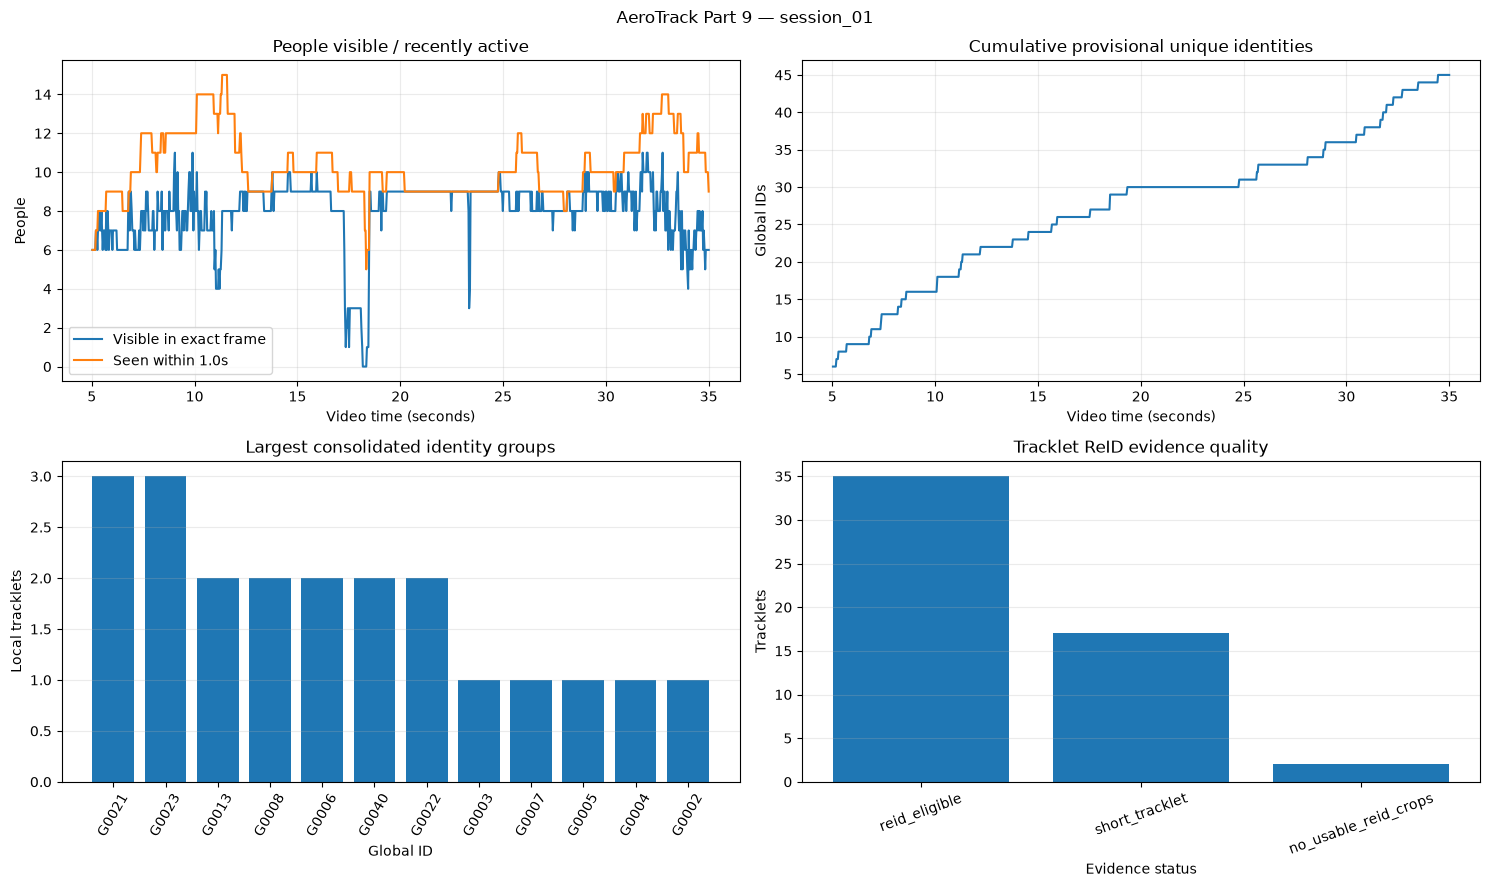

Saved dashboard: c:\Users\anyan\source\repos\AeroTrack\outputs\part9_tracklet_consolidation\session_01_part9_dashboard.png


In [14]:
DASHBOARD_PATHS = []

for video_id, timeline in frame_timelines.items():
    video_quality = track_quality[
        track_quality["video_id"] == video_id
    ]

    # Match exact video IDs. The identity table stores video_ids as tuples.
    video_groups = identity_membership[
        identity_membership["video_ids"].apply(
            lambda ids: video_id in ids
        )
    ].sort_values("tracklet_count", ascending=False).head(12)

    evidence_counts = (
        video_quality["evidence_status"]
        .value_counts()
    )

    fig, axes = plt.subplots(2, 2, figsize=(15, 9))

    axes[0, 0].plot(
        timeline["time_seconds"],
        timeline["visible_people"],
        label="Visible in exact frame"
    )
    axes[0, 0].plot(
        timeline["time_seconds"],
        timeline["recently_active_people"],
        label=f"Seen within {VISIBILITY_GRACE_SECONDS:.1f}s"
    )
    axes[0, 0].set_title("People visible / recently active")
    axes[0, 0].set_xlabel("Video time (seconds)")
    axes[0, 0].set_ylabel("People")
    axes[0, 0].legend()
    axes[0, 0].grid(True, alpha=0.25)

    axes[0, 1].plot(
        timeline["time_seconds"],
        timeline["cumulative_unique_people"]
    )
    axes[0, 1].set_title("Cumulative provisional unique identities")
    axes[0, 1].set_xlabel("Video time (seconds)")
    axes[0, 1].set_ylabel("Global IDs")
    axes[0, 1].grid(True, alpha=0.25)

    if not video_groups.empty:
        axes[1, 0].bar(
            video_groups["global_id"],
            video_groups["tracklet_count"]
        )
        axes[1, 0].tick_params(axis="x", rotation=60)
    axes[1, 0].set_title("Largest consolidated identity groups")
    axes[1, 0].set_xlabel("Global ID")
    axes[1, 0].set_ylabel("Local tracklets")
    axes[1, 0].grid(axis="y", alpha=0.25)

    axes[1, 1].bar(
        evidence_counts.index.astype(str),
        evidence_counts.values
    )
    axes[1, 1].set_title("Tracklet ReID evidence quality")
    axes[1, 1].set_xlabel("Evidence status")
    axes[1, 1].set_ylabel("Tracklets")
    axes[1, 1].tick_params(axis="x", rotation=20)
    axes[1, 1].grid(axis="y", alpha=0.25)

    fig.suptitle(f"AeroTrack Part 9 — {video_id}")
    fig.tight_layout()

    dashboard_path = PART9_DIR / f"{video_id}_part9_dashboard.png"
    fig.savefig(dashboard_path, dpi=150, bbox_inches="tight")
    DASHBOARD_PATHS.append(dashboard_path)

    plt.show()
    print("Saved dashboard:", dashboard_path)
    plt.close(fig)

## Section 15 — Create a new annotated video with consolidated Global IDs

The output video displays:
- Consolidated Global ID.
- Original local tracker ID.
- Current visible people.
- Recently active people.
- Cumulative provisional unique identities.

The video is rendered from the original footage and the existing tracking log. No detection or ReID inference is rerun.

In [15]:
def stable_color(identifier):
    digest = hashlib.md5(str(identifier).encode("utf-8")).digest()
    return (
        int(70 + digest[0] % 170),
        int(70 + digest[1] % 170),
        int(70 + digest[2] % 170)
    )


ANNOTATED_PATHS = []

if CREATE_ANNOTATED_VIDEO:
    for source in VIDEO_SOURCES:
        video_id = str(source["video_id"])
        meta = video_metadata[video_id]

        video_log = track_log[
            track_log["video_id"] == video_id
        ].copy()

        timeline = frame_timelines[video_id]
        metrics_by_frame = timeline.set_index("frame").to_dict("index")

        rows_by_frame = {
            int(frame_number): group
            for frame_number, group in video_log.groupby("frame")
        }

        max_local_frame = int(video_log["frame"].max())

        cap = cv2.VideoCapture(str(meta["video_path"]))
        cap.set(
            cv2.CAP_PROP_POS_MSEC,
            meta["segment_start_seconds"] * 1000
        )

        if not cap.isOpened():
            raise RuntimeError(f"{video_id}: could not reopen the video.")

        output_path = PART9_DIR / f"{video_id}_part9_consolidated.mp4"

        output_fps = (
            float(ANNOTATED_VIDEO_FPS)
            if ANNOTATED_VIDEO_FPS is not None
            else meta["fps"]
        )

        writer = cv2.VideoWriter(
            str(output_path),
            cv2.VideoWriter_fourcc(*"mp4v"),
            output_fps,
            (meta["width"], meta["height"])
        )

        if not writer.isOpened():
            cap.release()
            raise RuntimeError(f"Could not create annotated video: {output_path}")

        frame_number = 0
        render_start = time.time()

        while frame_number < max_local_frame:
            success, frame = cap.read()

            if not success:
                break

            frame_number += 1
            frame_rows = rows_by_frame.get(frame_number)
            metrics = metrics_by_frame.get(frame_number, {})

            if frame_rows is not None:
                for _, row in frame_rows.iterrows():
                    x1 = max(0, int(round(row["x1"])))
                    y1 = max(0, int(round(row["y1"])))
                    x2 = min(meta["width"] - 1, int(round(row["x2"])))
                    y2 = min(meta["height"] - 1, int(round(row["y2"])))

                    if x2 <= x1 or y2 <= y1:
                        continue

                    global_id = str(row["global_id"])
                    track_id = int(row["track_id"])
                    color = stable_color(global_id)

                    cv2.rectangle(
                        frame,
                        (x1, y1),
                        (x2, y2),
                        color,
                        2
                    )

                    label = f"{global_id} | T{track_id}"

                    cv2.putText(
                        frame,
                        label,
                        (x1, max(22, y1 - 7)),
                        cv2.FONT_HERSHEY_SIMPLEX,
                        max(0.45, min(0.75, meta["width"] / 5000)),
                        color,
                        2,
                        cv2.LINE_AA
                    )

            panel_lines = [
                f"AeroTrack Part 9 | {video_id}",
                f"Visible now: {int(metrics.get('visible_people', 0))}",
                f"Recently active: {int(metrics.get('recently_active_people', 0))}",
                f"Unique IDs seen: {int(metrics.get('cumulative_unique_people', 0))}",
                "Consolidated IDs are provisional"
            ]

            panel_x, panel_y = 20, 20
            font_scale = max(0.55, min(0.95, meta["width"] / 4000))
            line_height = int(32 * font_scale)
            panel_width = int(meta["width"] * 0.27)
            panel_height = line_height * len(panel_lines) + 20

            overlay = frame.copy()
            cv2.rectangle(
                overlay,
                (panel_x, panel_y),
                (panel_x + panel_width, panel_y + panel_height),
                (0, 0, 0),
                -1
            )
            frame = cv2.addWeighted(overlay, 0.55, frame, 0.45, 0)

            for line_index, text in enumerate(panel_lines):
                text_y = panel_y + 12 + (line_index + 1) * line_height

                cv2.putText(
                    frame,
                    text,
                    (panel_x + 12, text_y),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    font_scale,
                    (255, 255, 255),
                    2,
                    cv2.LINE_AA
                )

            writer.write(frame)

            if frame_number % 200 == 0:
                print(
                    f"{video_id}: rendered {frame_number}/{max_local_frame} frames"
                )

        cap.release()
        writer.release()

        ANNOTATED_PATHS.append(output_path)

        print(
            "Saved:", output_path,
            "| render seconds:", round(time.time() - render_start, 1)
        )

print("Annotated videos created:", len(ANNOTATED_PATHS))

session_01: rendered 200/899 frames
session_01: rendered 400/899 frames
session_01: rendered 600/899 frames
session_01: rendered 800/899 frames
Saved: c:\Users\anyan\source\repos\AeroTrack\outputs\part9_tracklet_consolidation\session_01_part9_consolidated.mp4 | render seconds: 79.0
Annotated videos created: 1


## Section 16 — Save Part 9 artefacts and final summary

The outputs include:
- Consolidated registry.
- Identity-group report.
- Merge-event log.
- Manual review queue.
- Tracklet quality report.
- Possible duplicate-box report.
- Per-frame count timeline.
- Visibility events.
- Per-video and combined summaries.
- Dashboard image(s).
- Annotated video(s).

The summary compares Part 8's provisional group count with the new Part 9 grouping result.

In [16]:
# Enrich the candidate table with the new Global IDs and merge status.
candidate_output = candidate_review.copy()
candidate_output["global_id_a"] = candidate_output["tracklet_a"].map(
    new_global_id_map
)
candidate_output["global_id_b"] = candidate_output["tracklet_b"].map(
    new_global_id_map
)
candidate_output["same_global_id_after_consolidation"] = (
    candidate_output["global_id_a"] == candidate_output["global_id_b"]
)

# Save the main data outputs.
consolidated_registry.to_csv(
    PART9_DIR / "consolidated_identity_registry.csv",
    index=False
)

identity_membership.to_csv(
    PART9_DIR / "identity_group_report.csv",
    index=False
)

merge_events.to_csv(
    PART9_DIR / "merge_events.csv",
    index=False
)

candidate_output.to_csv(
    PART9_DIR / "candidate_graph_with_new_global_ids.csv",
    index=False
)

review_updated.to_csv(
    PART9_DIR / "manual_merge_decisions.csv",
    index=False
)

track_quality.to_csv(
    PART9_DIR / "tracklet_quality_report.csv",
    index=False
)

duplicate_box_candidates.to_csv(
    PART9_DIR / "possible_same_frame_duplicate_boxes.csv",
    index=False
)

timeline_df.to_csv(
    PART9_DIR / "part9_frame_count_timeline.csv",
    index=False
)

visibility_events.to_csv(
    PART9_DIR / "part9_visibility_events.csv",
    index=False
)

video_summary.to_csv(
    PART9_DIR / "part9_video_count_summary.csv",
    index=False
)

combined_summary.to_csv(
    PART9_DIR / "part9_combined_count_summary.csv",
    index=False
)

# Summarize the resulting count and evidence.
accepted_merges = (
    int(merge_events["accepted"].sum())
    if not merge_events.empty else 0
)

multi_group_count = int(
    (identity_membership["tracklet_count"] > 1).sum()
)

tracklets_without_reid = int(
    (track_quality["evidence_status"] != "reid_eligible").sum()
)

review_candidate_count = int(
    (candidate_output["multi_mean_similarity"] >= REVIEW_THRESHOLD).sum()
)

summary = {
    "videos_processed": [str(source["video_id"]) for source in VIDEO_SOURCES],
    "raw_local_tracklets": int(track_log["tracklet_key"].nunique()),
    "part8_provisional_global_ids": previous_global_id_count,
    "part9_provisional_global_ids": int(
        consolidated_registry["global_id"].nunique()
    ),
    "reduction_vs_part8": int(
        previous_global_id_count -
        consolidated_registry["global_id"].nunique()
    ),
    "accepted_merge_edges": accepted_merges,
    "multi_tracklet_identity_groups": multi_group_count,
    "tracklets_without_usable_reid_crops": tracklets_without_reid,
    "candidate_pairs_for_review": review_candidate_count,
    "possible_same_frame_duplicate_box_pairs": int(
        len(duplicate_box_candidates)
    ),
    "direct_match_threshold": DIRECT_MATCH_THRESHOLD,
    "direct_min_margin": DIRECT_MIN_MARGIN,
    "chain_extension_threshold": CHAIN_EXTENSION_THRESHOLD,
    "chain_extension_min_margin": CHAIN_EXTENSION_MIN_MARGIN,
    "cluster_min_pair_similarity": CLUSTER_MIN_PAIR_SIMILARITY,
    "cross_video_auto_merges_enabled": ALLOW_CROSS_VIDEO_AUTO_MERGES,
    "video_summaries": video_summary.to_dict(orient="records"),
    "annotated_videos": [str(path) for path in ANNOTATED_PATHS],
    "dashboards": [str(path) for path in DASHBOARD_PATHS],
    "note": (
        "Global IDs are provisional tracklet clusters, not verified real-world "
        "identities. The count is not a statistical confidence interval and "
        "does not compensate for false detections or people missed by the detector. "
        "Visibility gaps are not proof of physical exit."
    )
}

SUMMARY_PATH = PART9_DIR / "part9_consolidation_summary.json"

with open(SUMMARY_PATH, "w", encoding="utf-8") as file:
    json.dump(summary, file, indent=2)

print("PART 9 SUMMARY")
display(pd.DataFrame([{
    "raw_local_tracklets": summary["raw_local_tracklets"],
    "part8_global_ids": summary["part8_provisional_global_ids"],
    "part9_global_ids": summary["part9_provisional_global_ids"],
    "reduction_vs_part8": summary["reduction_vs_part8"],
    "accepted_merge_edges": summary["accepted_merge_edges"],
    "multi_tracklet_identity_groups": summary["multi_tracklet_identity_groups"],
    "tracklets_without_usable_reid_crops": summary["tracklets_without_usable_reid_crops"],
    "candidate_pairs_for_review": summary["candidate_pairs_for_review"]
}]))

display(video_summary)
print("All Part 9 outputs saved under:", PART9_DIR)

PART 9 SUMMARY


,raw_local_tracklets,part8_global_ids,part9_global_ids,reduction_vs_part8,accepted_merge_edges,multi_tracklet_identity_groups,tracklets_without_usable_reid_crops,candidate_pairs_for_review
0,54,50,45,5,9,7,19,25


,video_id,detection_observations,local_tracklets,provisional_global_ids,multi_tracklet_global_groups,tracklets_without_usable_reid_crops,visible_people_final_frame,recently_active_final_frame,max_concurrent_visible_people,average_visible_people,cumulative_unique_final
0,session_01,7179,54,45,7,19,6,9,11,7.985539,45


All Part 9 outputs saved under: c:\Users\anyan\source\repos\AeroTrack\outputs\part9_tracklet_consolidation


## Section 17 — Optional: display the annotated result

Open the generated MP4 in Jupyter or directly from the Part 9 output folder.

In [17]:
if ANNOTATED_PATHS:
    print("Annotated video:", ANNOTATED_PATHS[0])
    display(Video(str(ANNOTATED_PATHS[0]), embed=False, width=1000))
else:
    print("No annotated video was generated.")

Annotated video: c:\Users\anyan\source\repos\AeroTrack\outputs\part9_tracklet_consolidation\session_01_part9_consolidated.mp4


## Section 18 — What to send back and how to approve extra matches

Please send:
1. The Part 9 summary from Section 16.
2. The multi-tracklet groups in `identity_group_report.csv`.
3. The updated dashboard image.
4. One screenshot from the new annotated video.
5. The top rows of `candidate_graph_with_new_global_ids.csv`.

### Optional manual merge review

Open:

`outputs/part9_tracklet_consolidation/manual_merge_decisions.csv`

Set `manual_decision` to `same`, `different` or `uncertain` for pairs you can confidently judge from the crop sheet or source video. Save the file and rerun Sections 6–16. The notebook preserves your decisions.

A manual `same` decision bypasses the appearance similarity floor, but the same-video temporal-overlap protection still applies. A `different` decision blocks that pair from being brought together through an identity chain.

### What the numbers mean

- `raw_local_tracklets`: number of BoT-SORT tracklets.
- `part9_provisional_global_ids`: number of groups after the current consolidation rules.
- `tracklets_without_usable_reid_crops`: tracklets that remain separate because appearance evidence was insufficient.
- `candidate_pairs_for_review`: pairs that may help reduce fragmentation but were not automatically merged.

The Part 9 global-ID count is a prototype grouping result. It is not a verified unique-person count or a guaranteed lower/upper bound on the actual number of people. Detector false positives, missed people and unresolved track fragments still affect it.

## Part 9 conclusion

AeroTrack now uses graph-based tracklet consolidation with mutual-best matching, chain extension, complete-link similarity checks, temporal overlap protection and manual overrides.

The next step is to inspect the updated groups and annotated video. We should only add more complexity if these results show that it is needed.